In [5]:
# Import required libraries
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Import KPCA_DA from the local module
from kpcada import KPCA_DA, load_expression_matrix

## Load Data
Load source (TCGA) and target (GSE45498) gene expression datasets.

In [6]:
# Define data paths
source_path = r"..\Data\TvsN\TCGA_BRCA_NvT_new.csv"
target_path =  r"..\Data\TvsN\GSE45498_NvT.csv"

# Load datasets
print("Loading source data (TCGA)...")
X_source, genes_source = load_expression_matrix(source_path)
print(f"Source shape: {X_source.shape} (genes x samples)")
print(f"Number of genes in source: {len(genes_source)}")

print("\nLoading target data (GSE45498)...")
X_target, genes_target = load_expression_matrix(target_path)
print(f"Target shape: {X_target.shape} (genes x samples)")
print(f"Number of genes in target: {len(genes_target)}")

Loading source data (TCGA)...
Source shape: (22489, 591) (genes x samples)
Number of genes in source: 22489

Loading target data (GSE45498)...
Target shape: (236, 183) (genes x samples)
Number of genes in target: 236
Source shape: (22489, 591) (genes x samples)
Number of genes in source: 22489

Loading target data (GSE45498)...
Target shape: (236, 183) (genes x samples)
Number of genes in target: 236


In [11]:
X_source.shape

(22489, 591)

## Initialize and Fit KPCA_DA Model
Create the KPCA_DA model with specified hyperparameters and fit it to align the domains.

In [7]:
# Initialize KPCA_DA model
model = KPCA_DA(
    n_components=2,        # Number of KPCA components
    kernel='rbf',          # Kernel type
    kpca_gamma=0.5,        # Gamma for KPCA kernel
    mmd_gamma=0.5,         # Gamma for MMD kernel
    lambda_reg=0.1,        # Regularization strength
    lr=0.0001,             # Learning rate
    epochs=100,            # Number of optimization epochs
    verbose=True           # Print progress
)

print("\nFitting KPCA_DA model...")
print("="*70)


Fitting KPCA_DA model...


In [8]:
# Fit and transform the data
Z_source, Z_target = model.fit_transform(
    X_source=X_source,
    X_target=X_target,
    genes_source=genes_source,
    genes_target=genes_target
)

print("\n" + "="*70)
print("Model fitting complete!")
print(f"Transformed source shape: {Z_source.shape}")
print(f"Transformed target shape: {Z_target.shape}")
print(f"Common genes found: {model.common_source_idx_.shape[0]}")

Epoch 0, Loss: 1.1405, MMD: 0.9999, Reg: 1.4054
Epoch 10, Loss: 1.1404, MMD: 0.9999, Reg: 1.4049
Epoch 20, Loss: 1.1404, MMD: 0.9999, Reg: 1.4045
Epoch 30, Loss: 1.1403, MMD: 0.9999, Reg: 1.4040
Epoch 40, Loss: 1.1403, MMD: 0.9999, Reg: 1.4035
Epoch 50, Loss: 1.1402, MMD: 0.9999, Reg: 1.4030
Epoch 60, Loss: 1.1402, MMD: 0.9999, Reg: 1.4025
Epoch 70, Loss: 1.1401, MMD: 0.9999, Reg: 1.4020
Epoch 80, Loss: 1.1401, MMD: 0.9999, Reg: 1.4015
Epoch 90, Loss: 1.1400, MMD: 0.9999, Reg: 1.4010

Model fitting complete!
Transformed source shape: (22489, 2)
Transformed target shape: (236, 2)
Common genes found: 228

Model fitting complete!
Transformed source shape: (22489, 2)
Transformed target shape: (236, 2)
Common genes found: 228


## Visualize Results
Plot the aligned source and target domains in the KPCA space.

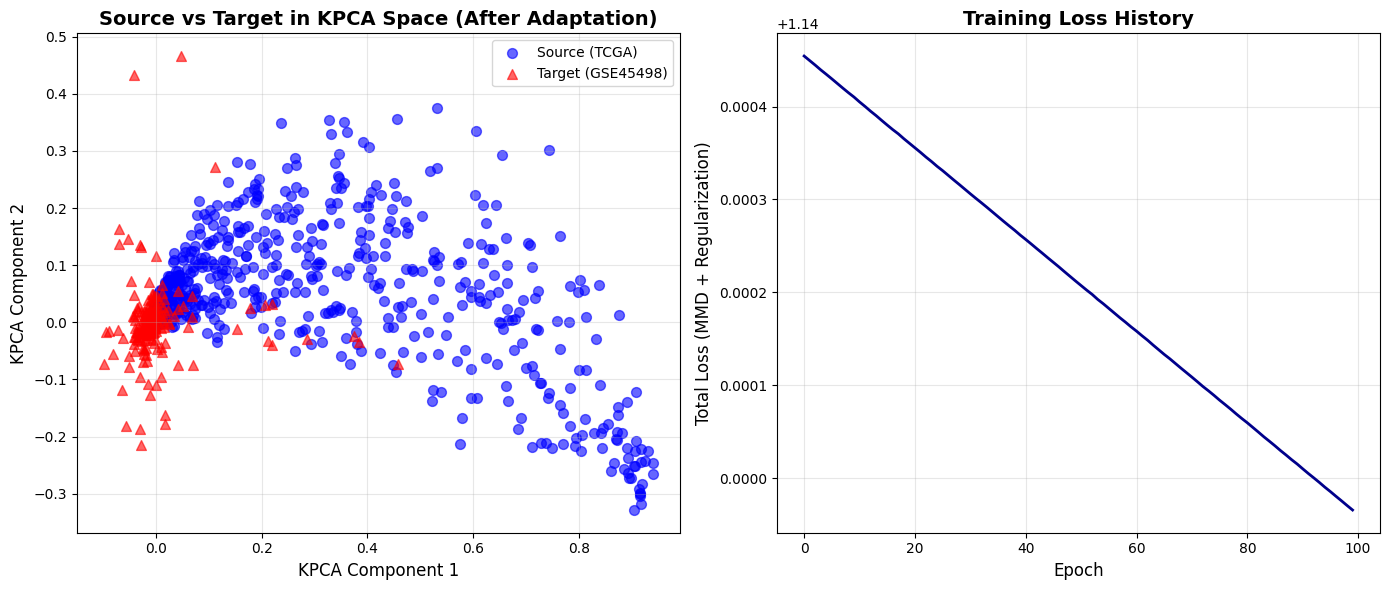

In [9]:
# Create visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot before adaptation (separate plots)
axes[0].scatter(Z_source[:, 0], Z_source[:, 1], alpha=0.6, s=50, c='blue', label='Source (TCGA)')
axes[0].scatter(Z_target[:, 0], Z_target[:, 1], alpha=0.6, s=50, c='red', label='Target (GSE45498)', marker='^')
axes[0].set_xlabel('KPCA Component 1', fontsize=12)
axes[0].set_ylabel('KPCA Component 2', fontsize=12)
axes[0].set_title('Source vs Target in KPCA Space (After Adaptation)', fontsize=14, fontweight='bold')
axes[0].legend(loc='best', fontsize=10)
axes[0].grid(True, alpha=0.3)

# Plot loss history
axes[1].plot(model.loss_history_, linewidth=2, color='darkblue')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Total Loss (MMD + Regularization)', fontsize=12)
axes[1].set_title('Training Loss History', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Analyze Common Genes
Check which genes are shared between source and target datasets.

In [15]:
# Get common genes
common_genes_source = genes_source[model.common_source_idx_]
common_genes_target = genes_target[model.common_target_idx_]

print(f"Total common genes: {len(common_genes_source)}")
print(f"\nFirst 20 common genes:")
print(common_genes_source[:20])

# Verify they match
print(f"\nGenes match between source and target: {np.array_equal(common_genes_source, common_genes_target)}")

Total common genes: 11254

First 20 common genes:
['A1CF' 'A2M' 'A4GALT' 'A4GNT' 'AAAS' 'AACS' 'AADAC' 'AAGAB' 'AAK1' 'AAMP'
 'AANAT' 'AASDHPPT' 'AASS' 'AATF' 'AATK' 'ABAT' 'ABCA11P' 'ABCA12' 'ABCA1'
 'ABCA2']

Genes match between source and target: False


## Summary Statistics
Display key statistics about the adaptation process.

In [9]:
print("KPCA-DA Summary")
print("="*70)
print(f"Source dataset:        {X_source.shape[0]} genes × {X_source.shape[1]} samples")
print(f"Target dataset:        {X_target.shape[0]} genes × {X_target.shape[1]} samples")
print(f"Common genes:          {len(common_genes_source)}")
print(f"KPCA components:       {model.n_components}")
print(f"Initial loss:          {model.loss_history_[0]:.6f}")
print(f"Final loss:            {model.loss_history_[-1]:.6f}")
print(f"Loss reduction:        {((model.loss_history_[0] - model.loss_history_[-1]) / model.loss_history_[0] * 100):.2f}%")
print("="*70)

KPCA-DA Summary
Source dataset:        22489 genes × 250 samples
Target dataset:        236 genes × 183 samples
Common genes:          228
KPCA components:       2
Initial loss:          1.174255
Final loss:            1.173619
Loss reduction:        0.05%


## Export Results (Optional)
Save the transformed data for further analysis.

In [ ]:
# Uncomment to save results
# np.save('Z_source_adapted.npy', Z_source)
# np.save('Z_target_adapted.npy', Z_target)
# print("Results saved!")